# Coarse HDF5：独立零值统计

本节独立于全部 raw 参数、读取和绘图 cell。重启 kernel 后，可以只从本节开始执行；不需要 `pyhdf`，也不会打开原始 HDF4。

实际默认目录为 `coarse_rh_12x20_sfr_v6`，对应 12×20 网格。默认包含配置中全部盘星系，缺目录明确报告。
**现有 coarse 文件只有逐格 MACER-LR baseline，没有由 Data-Set-11 保守归约的逐格真值。**
本节对所选 baseline 模式统计，图和表中均标明 baseline；不能把该结果当作 coarse 真值稀疏性。
`data_compatible` 是 canonical 模式，`paper_physical` 是另存的物理对照模式。

零值、正值、异常分类与 raw 一致：严格等于零、有限正值、NaN/Inf/负值；$p_N=N_0/N_{total}$。
时间使用 coarse HDF5 的 `time` 属性并核对 metadata，坐标使用文件保存的中心和边界。
对于配置中有显式重启时间映射的运行，另记录 `configured_time_gyr` 和 `time_mapping_mismatch`。
若旧 coarse 存储时间与当前配置不同，图和表会提示；本节不读取 raw 来校正，也不覆盖原 coarse 文件。

In [1]:
# Coarse 独立参数与配置 cell：只读 JSON 配置，不读取 raw 或 coarse snapshot。
import json
import re
import warnings
from numbers import Integral
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import PercentFormatter
from IPython.display import display

COARSE_PROJECT_ROOT_OVERRIDE = None
COARSE_DATA_ROOT_OVERRIDE = None  # 默认 BaseConfig.json 的 data_dir。
COARSE_DEFAULT_DIRNAME = 'coarse_rh_12x20_sfr_v6'
COARSE_SELECTION = None  # None：配置中的全部盘星系，使用默认 coarse 目录。
# 按星系指定目录，也可为同一星系指定多个目录：
# COARSE_SELECTION = {'fiducial': 'coarse_rh_12x20_sfr_v6', 'model_0_75': 'coarse_rh_8x8_sfr_v6'}
# COARSE_SELECTION = {'fiducial': ['coarse_rh_12x20_sfr_v6', 'coarse_rh_8x8_sfr_v6']}
COARSE_BASELINE_MODE = 'data_compatible'  # canonical baseline；也可指定 paper_physical。
COARSE_MAX_SNAPSHOTS = None  # None：全部现存帧；3：每个目录最多读取 3 帧。
COARSE_EXCLUDE_SNAPSHOTS = {}  # 如 {'fiducial': [0]}；torus 已知坏帧始终排除。
COARSE_TIME_UNIT = 'Gyr'  # 可选 Gyr、Myr、yr。
COARSE_PROGRESS_EVERY = 500


def coarse_project_root(override):
    if override is not None:
        root = Path(override).expanduser().resolve()
        if (root / '.config' / 'RawDataConfig.json').is_file():
            return root
        raise FileNotFoundError(f'项目配置不存在：{root}')
    current = Path.cwd().resolve()
    for root in [current, *current.parents]:
        if (root / '.config' / 'RawDataConfig.json').is_file():
            return root
    raise FileNotFoundError('请设置 COARSE_PROJECT_ROOT_OVERRIDE。')


COARSE_PROJECT_ROOT = coarse_project_root(COARSE_PROJECT_ROOT_OVERRIDE)
with (COARSE_PROJECT_ROOT / '.config' / 'BaseConfig.json').open(encoding='utf-8-sig') as stream:
    coarse_base_config = json.load(stream)
with (COARSE_PROJECT_ROOT / '.config' / 'RawDataConfig.json').open(encoding='utf-8-sig') as stream:
    coarse_disk_config = json.load(stream)['disk_galaxy']
COARSE_DATA_ROOT = Path(COARSE_DATA_ROOT_OVERRIDE or coarse_base_config['data_dir']).expanduser()
if not COARSE_DATA_ROOT.is_absolute():
    COARSE_DATA_ROOT = COARSE_PROJECT_ROOT / COARSE_DATA_ROOT
COARSE_DATA_ROOT = COARSE_DATA_ROOT.resolve()


def coarse_galaxy_key(name):
    if not isinstance(name, str):
        raise TypeError('星系名称必须是字符串。')
    key = name.removeprefix('disk_galaxy_')
    if key not in coarse_disk_config:
        raise KeyError(f'未知盘星系 {name!r}；可选：{list(coarse_disk_config)}')
    return key


def coarse_indices(values):
    if isinstance(values, Integral) and not isinstance(values, bool):
        values = [values]
    result = []
    for value in values:
        if isinstance(value, bool) or not isinstance(value, Integral) or value < 0:
            raise ValueError(f'snapshot 编号必须为非负整数：{value!r}')
        result.append(int(value))
    return list(dict.fromkeys(result))


def coarse_directory_name(value):
    if not isinstance(value, str) or not value or value in {'.', '..'} or any(c in value for c in '/\\'):
        raise ValueError(f'coarse 名称必须是单层目录名：{value!r}')
    return value.replace('×', 'x')


coarse_requested = ({key: COARSE_DEFAULT_DIRNAME for key in coarse_disk_config}
                    if COARSE_SELECTION is None else COARSE_SELECTION)
COARSE_DATASETS = []
for name, directories in coarse_requested.items():
    key = coarse_galaxy_key(name)
    if isinstance(directories, str):
        directories = [directories]
    for directory in directories:
        pair = (key, coarse_directory_name(directory))
        if pair not in COARSE_DATASETS:
            COARSE_DATASETS.append(pair)
if not COARSE_DATASETS:
    raise ValueError('至少选择一组 coarse 数据。')
if COARSE_BASELINE_MODE not in {'data_compatible', 'paper_physical'}:
    raise ValueError('COARSE_BASELINE_MODE 只能是 data_compatible 或 paper_physical。')
if COARSE_TIME_UNIT not in {'Gyr', 'Myr', 'yr'}:
    raise ValueError('COARSE_TIME_UNIT 只能是 Gyr、Myr 或 yr。')
if COARSE_MAX_SNAPSHOTS is not None and (isinstance(COARSE_MAX_SNAPSHOTS, bool)
        or not isinstance(COARSE_MAX_SNAPSHOTS, Integral) or COARSE_MAX_SNAPSHOTS <= 0):
    raise ValueError('COARSE_MAX_SNAPSHOTS 必须是正整数或 None。')
if isinstance(COARSE_PROGRESS_EVERY, bool) or not isinstance(COARSE_PROGRESS_EVERY, Integral) or COARSE_PROGRESS_EVERY <= 0:
    raise ValueError('COARSE_PROGRESS_EVERY 必须是正整数。')
COARSE_EXCLUDED = {key: set() for key in coarse_disk_config}
if 'torus_100yr' in COARSE_EXCLUDED:
    COARSE_EXCLUDED['torus_100yr'] = {747, 754, 755, 763, 764, 765, 766, 767, 768, 769, 770}
for name, indices in COARSE_EXCLUDE_SNAPSHOTS.items():
    COARSE_EXCLUDED[coarse_galaxy_key(name)].update(coarse_indices(indices))
print(f'Coarse 数据根目录：{COARSE_DATA_ROOT}')
display(pd.DataFrame(COARSE_DATASETS, columns=['galaxy', 'coarse_dir']))


Coarse 数据根目录：D:\research\ai+MACERsimulation\MACNet-v1\data


,galaxy,coarse_dir
0,fiducial,coarse_rh_12x20_sfr_v6
1,fiducial_4,coarse_rh_12x20_sfr_v6
2,fiducial_7,coarse_rh_12x20_sfr_v6
3,model_0_75,coarse_rh_12x20_sfr_v6
4,model_1_1,coarse_rh_12x20_sfr_v6
5,torus_100yr,coarse_rh_12x20_sfr_v6
6,fiducial_10,coarse_rh_12x20_sfr_v6


In [3]:
# Coarse 专用读取与统计函数 cell：不调用 raw 函数，也不打开任何 HDF4 文件。
def coarse_files(key, directory):
    folder = COARSE_DATA_ROOT / f'disk_galaxy_{key}' / directory
    if not folder.is_dir():
        raise FileNotFoundError(f'coarse 目录不存在：{folder}')
    indexed = {}
    for path in folder.iterdir():
        if not path.is_file() or path.suffix.lower() not in {'.h5', '.hdf5'} or not path.stem.isdigit():
            continue
        index = int(path.stem)
        if index in indexed:
            raise ValueError(f'coarse 目录有重复编号 {index}：{folder}')
        indexed[index] = path
    if not indexed:
        raise FileNotFoundError(f'没有数字编号的 HDF5 snapshot：{folder}')
    return dict(sorted(indexed.items()))


def coarse_classify(sfr):
    categories = np.full(sfr.shape, 2, dtype=np.uint8)
    categories[np.isfinite(sfr) & (sfr == 0)] = 0
    categories[np.isfinite(sfr) & (sfr > 0)] = 1
    return categories


def coarse_summarize(sfr):
    counts = np.bincount(coarse_classify(sfr).ravel(), minlength=3)
    return dict(n_total=int(sfr.size), n_zero=int(counts[0]), n_nonzero=int(counts[1]),
                n_abnormal=int(counts[2]), p_N=float(counts[0] / sfr.size),
                p_abnormal=float(counts[2] / sfr.size))


def read_coarse_sfr(path, key, mode):
    if mode not in {'data_compatible', 'paper_physical'}:
        raise ValueError('请先明确选择 COARSE_BASELINE_MODE；此处不会把 baseline 当成真值。')
    dataset_path = f'sfr_supervision/{mode}/cell_sfr_baseline'
    with h5py.File(path, 'r') as handle:
        if int(handle.attrs.get('processed_format_version', -1)) != 6:
            raise ValueError('仅支持二维 format-version 6 coarse HDF5。')
        raw_metadata = handle['metadata/contract_json'][()]
        if isinstance(raw_metadata, bytes):
            raw_metadata = raw_metadata.decode('utf-8')
        metadata = json.loads(raw_metadata)
        source = metadata['source']
        expected_id = f'disk_galaxy_{key}'
        if source['galaxy_id'] != expected_id or source.get('simulation_code') != 'MACER2D':
            raise ValueError(f'来源身份与所选盘星系不一致：{source}')
        if metadata['geometry']['spatial_axis_order'] != ['theta', 'r'] or metadata['geometry']['ndim'] != 2:
            raise ValueError('空间轴顺序必须为 (theta,r)，且 ndim=2。')
        if metadata['derivation']['operator_id'] == 'identity_fine':
            raise ValueError('所选文件是 fine，不能当作 coarse。')
        index = source['raw_snapshot_index']
        if isinstance(index, bool) or not isinstance(index, Integral) or index < 0 or int(index) != int(Path(path).stem):
            raise ValueError('metadata 原始编号与 coarse 文件名不一致，拒绝猜测单帧身份。')
        time_gyr = float(handle.attrs['time'])
        if (not np.isfinite(time_gyr) or time_gyr < 0 or source.get('time_units') != 'Gyr'
                or not np.isclose(time_gyr, float(source['time']), rtol=0, atol=1e-12)):
            raise ValueError('coarse 时间无效或与 metadata 不一致。')
        configured_time_gyr = np.nan
        mapping = coarse_disk_config[key].get('time_mapping')
        if mapping is not None:
            if mapping.get('mode') != 'segmented_restart_absolute':
                raise ValueError('无法核对未知的配置时间映射。')
            if int(index) == 0:
                configured_time_gyr = float(mapping['index_zero_time'])
            else:
                completed = (int(index)-1) // int(mapping['segment_cycle_size'])
                steps = int(index) + completed * int(mapping['extra_time_steps_per_segment'])
                configured_time_gyr = (float(mapping['positive_index_offset'])
                                      + steps * float(coarse_disk_config[key]['snapshot_dt']))
        time_mapping_mismatch = (np.isfinite(configured_time_gyr)
                                 and not np.isclose(time_gyr, configured_time_gyr, rtol=0, atol=1e-9))
        sfr = np.asarray(handle[dataset_path][()], dtype=np.float64)
        r = np.asarray(handle['coordinates/axis_0'][()], dtype=np.float64)
        theta = np.asarray(handle['coordinates/axis_1'][()], dtype=np.float64)
        r_edges = np.asarray(handle['coordinates/axis_0_edges'][()], dtype=np.float64)
        theta_edges = np.asarray(handle['coordinates/axis_1_edges'][()], dtype=np.float64)
        mode_group = handle[f'sfr_supervision/{mode}']
        baseline_total = float(mode_group.attrs['baseline_total'])
        canonical = handle['sfr_supervision/canonical']
        y, b, c = (float(canonical[name][()]) for name in ['Y_alpha', 'B_alpha', 'C_alpha_true'])
        if not np.all(np.isfinite([y, b, c])) or not np.isclose(y, b+c, rtol=1e-10, atol=1e-12):
            raise ValueError('canonical Y=B+C 恒等式不成立。')
        if mode == 'data_compatible' and not np.isclose(baseline_total, b, rtol=1e-10, atol=1e-12):
            raise ValueError('所选 canonical baseline 总量不一致。')
        identity = metadata['identity']
        if not identity.get('sample_uid') or not identity.get('parent_hr_uid'):
            raise ValueError('缺少 sample_uid 或 parent_hr_uid。')
    if (r.ndim != 1 or theta.ndim != 1 or not r.size or not theta.size
            or sfr.shape != (theta.size, r.size)):
        raise ValueError('SFR shape 与 (N_theta,N_r) 不一致。')
    for centers, edges in [(r, r_edges), (theta, theta_edges)]:
        if (edges.shape != (centers.size+1,) or not np.all(np.isfinite(centers))
                or not np.all(np.isfinite(edges)) or np.any(np.diff(centers) <= 0)
                or np.any(np.diff(edges) <= 0) or np.any(centers <= edges[:-1]) or np.any(centers >= edges[1:])):
            raise ValueError('coarse 坐标中心与边界无效。')
    if np.any(r_edges <= 0) or theta_edges[0] < 0 or theta_edges[-1] > np.pi+1e-12:
        raise ValueError('coarse 球坐标边界超出有效范围。')
    if np.all(np.isfinite(sfr)) and np.all(sfr >= 0):
        if not np.isclose(np.sum(sfr, dtype=np.float64), baseline_total, rtol=1e-10, atol=1e-12):
            raise ValueError('逐格 baseline 之和与保存的 baseline_total 不一致。')
    signature = json.dumps({'derivation': metadata['derivation'], 'shape': list(sfr.shape),
                            'mode': mode}, sort_keys=True)
    return dict(sfr=sfr, r=r, theta=theta, r_edges=r_edges, theta_edges=theta_edges,
                time_gyr=time_gyr, configured_time_gyr=configured_time_gyr, time_mapping_mismatch=bool(time_mapping_mismatch),
                snapshot_index=int(index), sample_uid=identity['sample_uid'],
                parent_hr_uid=identity['parent_hr_uid'], signature=signature, sfr_source=dataset_path)


COARSE_STATS_COLUMNS = ['galaxy', 'coarse_dir', 'baseline_mode', 'snapshot_index', 'time_gyr',
                       'configured_time_gyr', 'time_mapping_mismatch', 'file', 'sfr_source', 'sample_uid', 'parent_hr_uid', 'n_total', 'n_zero',
                       'n_nonzero', 'n_abnormal', 'p_N', 'p_abnormal', 'status', 'error']


def scan_coarse(datasets, mode, limit=None):
    if mode not in {'data_compatible', 'paper_physical'}:
        raise ValueError('请先设置 COARSE_BASELINE_MODE。')
    records, summaries = [], []
    for key, directory in datasets:
        try:
            indexed = coarse_files(key, directory)
        except (OSError, ValueError) as exc:
            summaries.append(dict(galaxy=key, coarse_dir=directory, status='unavailable', error=str(exc)))
            print(f'{key}/{directory}：{exc}')
            continue
        excluded = set(indexed).intersection(COARSE_EXCLUDED[key])
        eligible = [index for index in indexed if index not in excluded]
        chosen = eligible if limit is None else eligible[:limit]
        reference_signature = None
        seen_uids = set()
        for index in sorted(excluded):
            records.append(dict(galaxy=key, coarse_dir=directory, baseline_mode=mode, snapshot_index=index,
                                file=str(indexed[index]), status='excluded', error='排除清单；未读取'))
        for position, index in enumerate(chosen, 1):
            row = dict(galaxy=key, coarse_dir=directory, baseline_mode=mode, snapshot_index=index,
                       file=str(indexed[index]), error='')
            try:
                frame = read_coarse_sfr(indexed[index], key, mode)
                if reference_signature is not None and frame['signature'] != reference_signature:
                    raise ValueError('同一 coarse 目录混有不同算子/shape/参数契约。')
                if frame['sample_uid'] in seen_uids:
                    raise ValueError('目录中存在重复 sample_uid。')
                reference_signature = frame['signature']
                seen_uids.add(frame['sample_uid'])
                row.update(coarse_summarize(frame['sfr']))
                row.update({name: frame[name] for name in ['time_gyr','configured_time_gyr','time_mapping_mismatch','sfr_source','sample_uid','parent_hr_uid']})
                row['status'] = 'abnormal' if row['n_abnormal'] else 'ok'
            except (OSError, ValueError, KeyError, TypeError) as exc:
                row.update(status='read_error', error=f'{type(exc).__name__}: {exc}')
            records.append(row)
            if position % COARSE_PROGRESS_EVERY == 0 or position == len(chosen):
                print(f'{key}/{directory}：已读取 {position}/{len(chosen)} 帧')
        indices = list(indexed)
        summaries.append(dict(galaxy=key, coarse_dir=directory, status='scanned', error='',
                              n_discovered=len(indexed), n_attempted=len(chosen), n_excluded=len(excluded),
                              n_missing_between_files=indices[-1]-indices[0]+1-len(indexed),
                              limited=limit is not None and len(chosen)<len(eligible)))
    return pd.DataFrame(records, columns=COARSE_STATS_COLUMNS), pd.DataFrame(summaries)


## Coarse 全序列读取

只读取所选 coarse HDF5；不读取原始 HDF4，也不重算 SFR 算子。缺目录、损坏文件、契约错误单独报告。
同一目录内 shape、粗粒化算子及参数必须一致。`coarse_zero_stats` 与 raw 的 `zero_stats` 独立保存。

In [4]:
# Coarse 全序列读取 cell；单帧绘图不要求运行本 cell。
coarse_zero_stats, coarse_run_summary = scan_coarse(COARSE_DATASETS, COARSE_BASELINE_MODE, COARSE_MAX_SNAPSHOTS)
display(coarse_run_summary)
display(coarse_zero_stats.head(12))
if not coarse_zero_stats.empty:
    display(coarse_zero_stats.groupby(['galaxy','coarse_dir','status']).size().rename('n_snapshots').reset_index())
    coarse_problems = coarse_zero_stats.loc[coarse_zero_stats['status'].isin(['abnormal','read_error'])]
    if not coarse_problems.empty:
        display(coarse_problems.head(20))


fiducial/coarse_rh_12x20_sfr_v6：已读取 500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 1000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 1500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 2000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 2500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 3000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 3500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 4000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 4500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 5000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 5500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 6000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 6500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 7000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 7500/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 8000/8475 帧
fiducial/coarse_rh_12x20_sfr_v6：已读取 8475/8475 帧
fiducial_4/coarse_rh_12x20_sfr_v6：已读取 500/8816 帧
fiducial_4/coarse_rh_12x20_sfr_v6：已读取 1000/8816 帧
fiducial_4/coarse_rh_12x20_sfr_v6：已读取 1500/8816 帧
fiducial_4/coarse_rh_12x20_sfr_v6：已读

,galaxy,coarse_dir,status,error,n_discovered,n_attempted,n_excluded,n_missing_between_files,limited
0,fiducial,coarse_rh_12x20_sfr_v6,scanned,,8475.0,8475.0,0.0,1057.0,False
1,fiducial_4,coarse_rh_12x20_sfr_v6,scanned,,8816.0,8816.0,0.0,716.0,False
2,fiducial_7,coarse_rh_12x20_sfr_v6,scanned,,7071.0,7071.0,0.0,2461.0,False
3,model_0_75,coarse_rh_12x20_sfr_v6,scanned,,954.0,954.0,0.0,0.0,False
4,model_1_1,coarse_rh_12x20_sfr_v6,scanned,,954.0,954.0,0.0,0.0,False
5,torus_100yr,coarse_rh_12x20_sfr_v6,scanned,,989.0,989.0,0.0,11.0,False
6,fiducial_10,coarse_rh_12x20_sfr_v6,unavailable,coarse 目录不存在：D:\research\ai+MACERsimulation\MA...,NaN,NaN,NaN,NaN,NaN


,galaxy,coarse_dir,baseline_mode,snapshot_index,time_gyr,configured_time_gyr,time_mapping_mismatch,file,sfr_source,sample_uid,parent_hr_uid,n_total,n_zero,n_nonzero,n_abnormal,p_N,p_abnormal,status,error
0,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,0,0.00000,0.00000,False,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:25e4b56132c36e038c3d,macerhr:7aa673463572b2a0083b,240,176,64,0,0.733333,0.0,ok,
1,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,1,0.00125,0.56375,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:cbb05cd8a4b1b3197057,macerhr:c010f83f5d6e56164bc9,240,217,23,0,0.904167,0.0,ok,
2,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,2,0.00250,0.56500,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:7ee5a8b72b9c2b76b9bf,macerhr:b51e93d66bdb2c1e04e5,240,224,16,0,0.933333,0.0,ok,
3,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,3,0.00375,0.56625,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:c6b6c45f6c94bbc0e2dc,macerhr:42f77e6df6616d887cdb,240,224,16,0,0.933333,0.0,ok,
4,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,4,0.00500,0.56750,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:2f96a1b8c676e813f725,macerhr:1e3884441024887a4029,240,223,17,0,0.929167,0.0,ok,
5,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,5,0.00625,0.56875,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:f3fdff809718b0215aa0,macerhr:bce12dfe3b98a93a9301,240,223,17,0,0.929167,0.0,ok,
6,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,6,0.00750,0.57000,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:7c7b86e0cf83f2d67b9d,macerhr:1822d13f1da4d26564e1,240,224,16,0,0.933333,0.0,ok,
7,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,7,0.00875,0.57125,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:ce69fd68ed3589a969d5,macerhr:1c03c791f5bec39cac7a,240,223,17,0,0.929167,0.0,ok,
8,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,8,0.01000,0.57250,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:bb4481e2dc8a3b659020,macerhr:6de7f153281754fbf6e9,240,223,17,0,0.929167,0.0,ok,
9,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,9,0.01125,0.57375,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,macnetsample:9b82c9a64ad4d8379ab2,macerhr:04d1581e57af9f8453e7,240,223,17,0,0.929167,0.0,ok,


,galaxy,coarse_dir,status,n_snapshots
0,fiducial,coarse_rh_12x20_sfr_v6,ok,8475
1,fiducial_4,coarse_rh_12x20_sfr_v6,ok,8816
2,fiducial_7,coarse_rh_12x20_sfr_v6,ok,7071
3,model_0_75,coarse_rh_12x20_sfr_v6,ok,954
4,model_1_1,coarse_rh_12x20_sfr_v6,ok,954
5,torus_100yr,coarse_rh_12x20_sfr_v6,ok,989


## Coarse 时间演化图

本 cell 只使用 `coarse_zero_stats`，每个星系、每个 coarse 目录分别绘图，纵轴自适应。
同标签时间保留全部帧；缺号/读取失败/排除处断线，严格时间倒退另报。图中明确标注 baseline 模式。

横轴明确标为 Stored coarse time；若当前显式配置映射与文件保存时间不同，会报告差异。


C:\Users\augus\AppData\Local\Temp\ipykernel_47348\3100207411.py:14: UserWarning: fiducial/coarse_rh_12x20_sfr_v6 有 8474 帧 coarse 存储时间与当前配置映射不符；本图保留文件存储时间，未修改数据。示例：[{'snapshot_index': 1, 'time_gyr': 0.00125, 'configured_time_gyr': 0.56375}, {'snapshot_index': 2, 'time_gyr': 0.0025, 'configured_time_gyr': 0.565}, {'snapshot_index': 3, 'time_gyr': 0.00375, 'configured_time_gyr': 0.56625}]
  warnings.warn(f'{key}/{directory} 有 {len(mismatched)} 帧 coarse 存储时间与当前配置映射不符；'


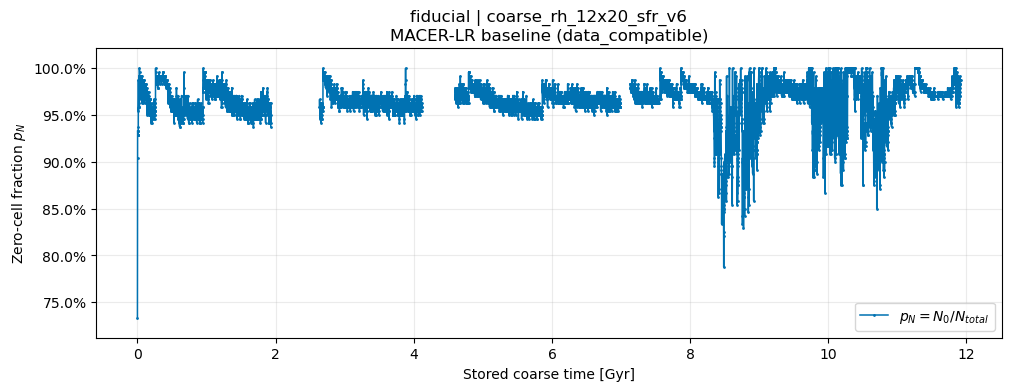

C:\Users\augus\AppData\Local\Temp\ipykernel_47348\3100207411.py:14: UserWarning: fiducial_4/coarse_rh_12x20_sfr_v6 有 8815 帧 coarse 存储时间与当前配置映射不符；本图保留文件存储时间，未修改数据。示例：[{'snapshot_index': 1, 'time_gyr': 0.00125, 'configured_time_gyr': 0.56375}, {'snapshot_index': 2, 'time_gyr': 0.0025, 'configured_time_gyr': 0.565}, {'snapshot_index': 3, 'time_gyr': 0.00375, 'configured_time_gyr': 0.56625}]
  warnings.warn(f'{key}/{directory} 有 {len(mismatched)} 帧 coarse 存储时间与当前配置映射不符；'


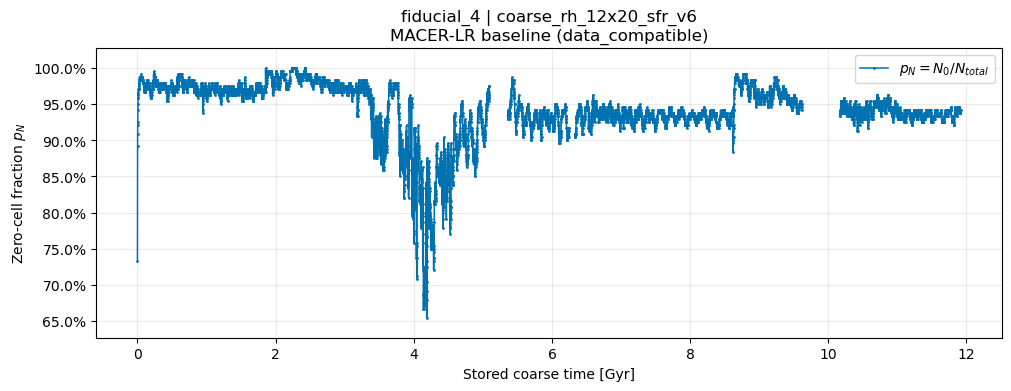

C:\Users\augus\AppData\Local\Temp\ipykernel_47348\3100207411.py:14: UserWarning: fiducial_7/coarse_rh_12x20_sfr_v6 有 7070 帧 coarse 存储时间与当前配置映射不符；本图保留文件存储时间，未修改数据。示例：[{'snapshot_index': 1, 'time_gyr': 0.00125, 'configured_time_gyr': 0.56375}, {'snapshot_index': 2, 'time_gyr': 0.0025, 'configured_time_gyr': 0.565}, {'snapshot_index': 3, 'time_gyr': 0.00375, 'configured_time_gyr': 0.56625}]
  warnings.warn(f'{key}/{directory} 有 {len(mismatched)} 帧 coarse 存储时间与当前配置映射不符；'


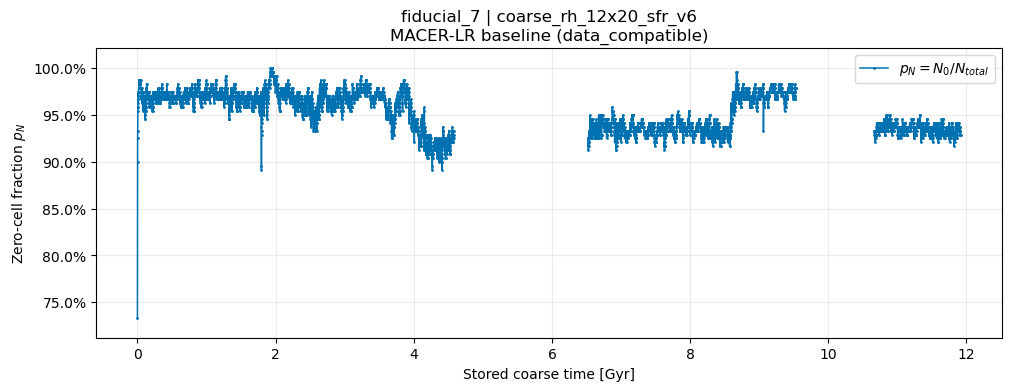

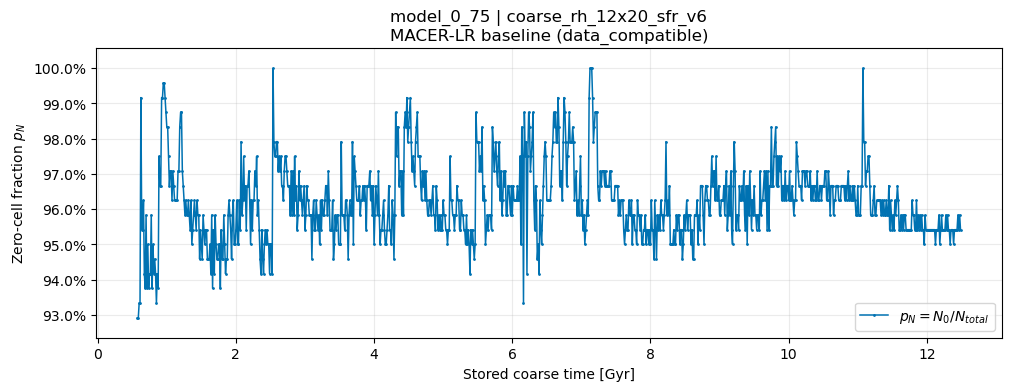

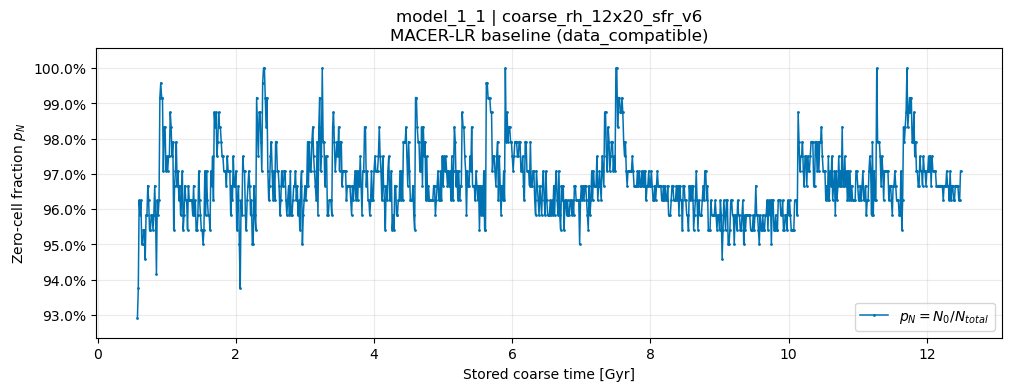

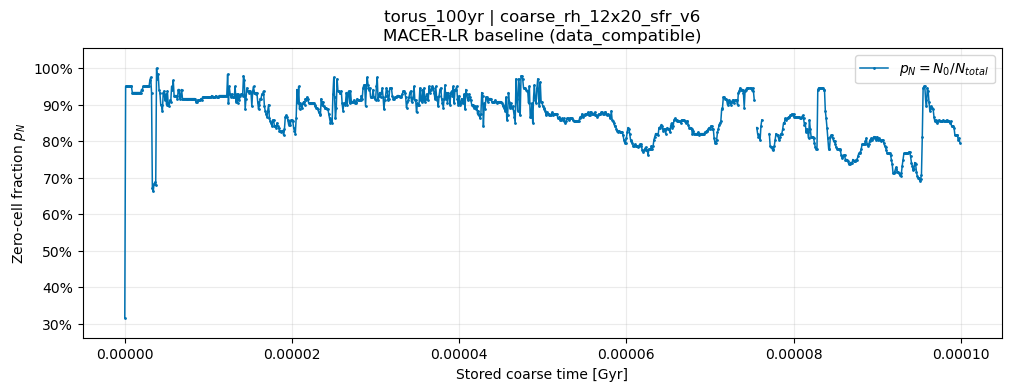

fiducial_10/coarse_rh_12x20_sfr_v6：没有可用的 coarse 时间曲线。


In [7]:
# Coarse 时间曲线绘图 cell：与 raw 时间曲线 cell 分离，不重新读取文件。
def plot_coarse_evolution(stats, datasets, mode, time_unit):
    figures = {}
    scale = {'Gyr':1., 'Myr':1e3, 'yr':1e9}[time_unit]
    for key, directory in datasets:
        rows = stats.loc[stats['galaxy'].eq(key) & stats['coarse_dir'].eq(directory)
                         & stats['baseline_mode'].eq(mode)].sort_values('snapshot_index')
        if rows.empty or not rows['p_N'].notna().any():
            print(f'{key}/{directory}：没有可用的 coarse 时间曲线。')
            continue
        mismatched = rows.loc[rows['time_mapping_mismatch'].eq(True)]
        if not mismatched.empty:
            example = mismatched[['snapshot_index','time_gyr','configured_time_gyr']].head(3).to_dict('records')
            warnings.warn(f'{key}/{directory} 有 {len(mismatched)} 帧 coarse 存储时间与当前配置映射不符；'
                          f'本图保留文件存储时间，未修改数据。示例：{example}')
        fig, ax = plt.subplots(figsize=(10,3.8), constrained_layout=True)
        xs, ys, reversals = [], [], []
        previous = None
        for row in rows.itertuples(index=False):
            if not np.isfinite(row.time_gyr) or not np.isfinite(row.p_N):
                xs.append(np.nan); ys.append(np.nan); previous = None
                continue
            if previous is not None:
                if row.snapshot_index != previous[0]+1 or row.time_gyr < previous[1]:
                    xs.append(np.nan); ys.append(np.nan)
                if row.time_gyr < previous[1]:
                    reversals.append((previous[0],row.snapshot_index,previous[1],row.time_gyr))
            xs.append(row.time_gyr*scale); ys.append(row.p_N)
            previous = (row.snapshot_index,row.time_gyr)
        if reversals:
            warnings.warn(f'{key}/{directory} coarse 时间严格倒退，已断线：{reversals[:3]}')
        ax.plot(xs,ys,color='#0072B2',linewidth=1.1,marker='.',markersize=2,label=r'$p_N=N_0/N_{total}$')
        bad = rows.loc[rows['n_abnormal'].gt(0) & rows['p_N'].notna()]
        if not bad.empty:
            ax.scatter(bad['time_gyr']*scale,bad['p_N'],color='#D55E00',marker='x',label='Abnormal cells present')
        ax.set(title=f'{key} | {directory}\nMACER-LR baseline ({mode})',
               xlabel=f'Stored coarse time [{time_unit}]',ylabel=r'Zero-cell fraction $p_N$')
        ax.margins(y=0.08)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.))
        ax.grid(alpha=.25); ax.legend(loc='best')
        figures[(key,directory)] = fig
        plt.show()
    return figures


if 'coarse_zero_stats' not in globals():
    raise RuntimeError('请先运行 coarse 全序列读取 cell。')
coarse_evolution_figures = plot_coarse_evolution(coarse_zero_stats,COARSE_DATASETS,COARSE_BASELINE_MODE,COARSE_TIME_UNIT)


## Coarse 指定单帧掩码

在下方 cell 顶部修改 `COARSE_MASK_SNAPSHOTS`，直接运行该 cell。无需读取 raw，也无需运行 coarse 全序列扫描。
简写 `{'fiducial':[0,100]}` 使用默认 coarse 目录；嵌套字典可指定其他目录。
编号取 metadata 中的原始 snapshot index，并核对文件名。
蓝色为零，橙色为正，紫红色为异常；使用 coarse 文件保存的真实坐标边界。

C:\Users\augus\AppData\Local\Temp\ipykernel_47348\2951881468.py:51: UserWarning: fiducial/coarse_rh_12x20_sfr_v6/9000 coarse 存储时间 11.25 Gyr 与当前配置 11.82375 Gyr 不符；图中保留存储时间。
  warnings.warn(f'{key}/{directory}/{index} coarse 存储时间 {frame["time_gyr"]} Gyr '


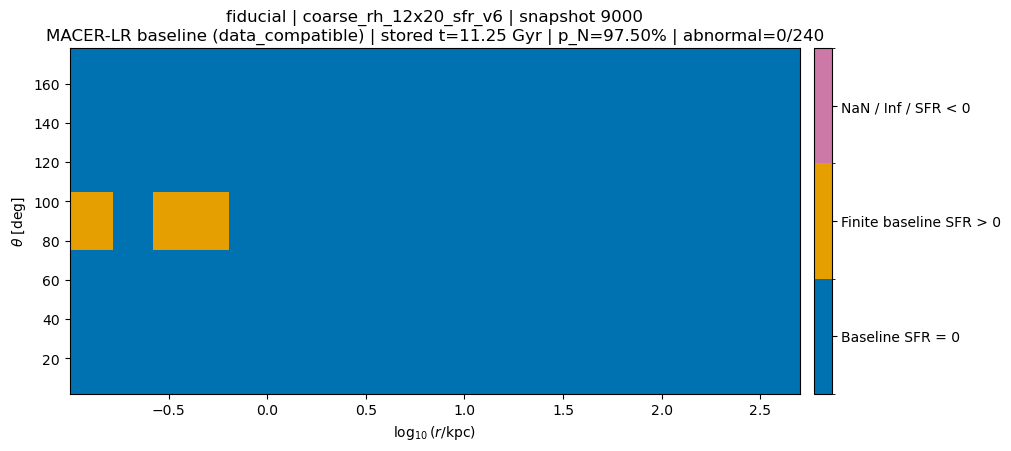

C:\Users\augus\AppData\Local\Temp\ipykernel_47348\2951881468.py:51: UserWarning: fiducial/coarse_rh_12x20_sfr_v6/9001 coarse 存储时间 11.25125 Gyr 与当前配置 11.825000000000001 Gyr 不符；图中保留存储时间。
  warnings.warn(f'{key}/{directory}/{index} coarse 存储时间 {frame["time_gyr"]} Gyr '


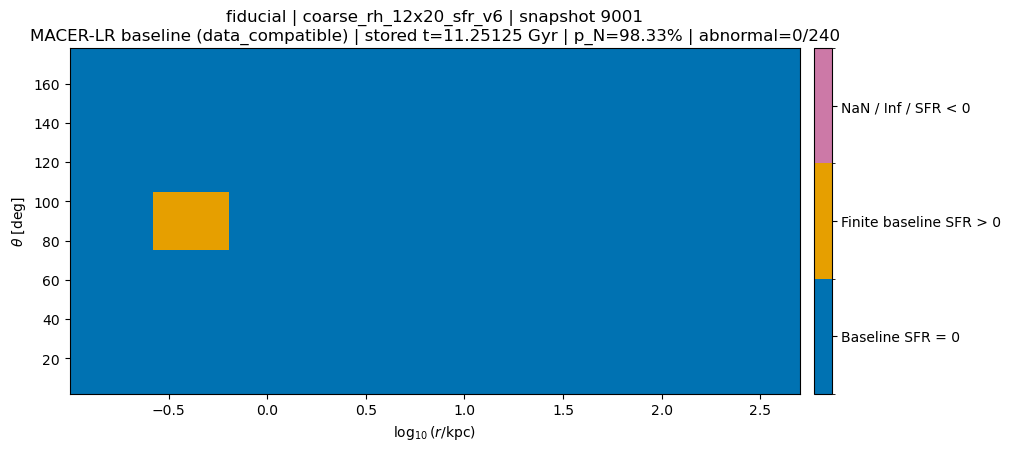

C:\Users\augus\AppData\Local\Temp\ipykernel_47348\2951881468.py:51: UserWarning: fiducial/coarse_rh_12x20_sfr_v6/9002 coarse 存储时间 11.2525 Gyr 与当前配置 11.82625 Gyr 不符；图中保留存储时间。
  warnings.warn(f'{key}/{directory}/{index} coarse 存储时间 {frame["time_gyr"]} Gyr '


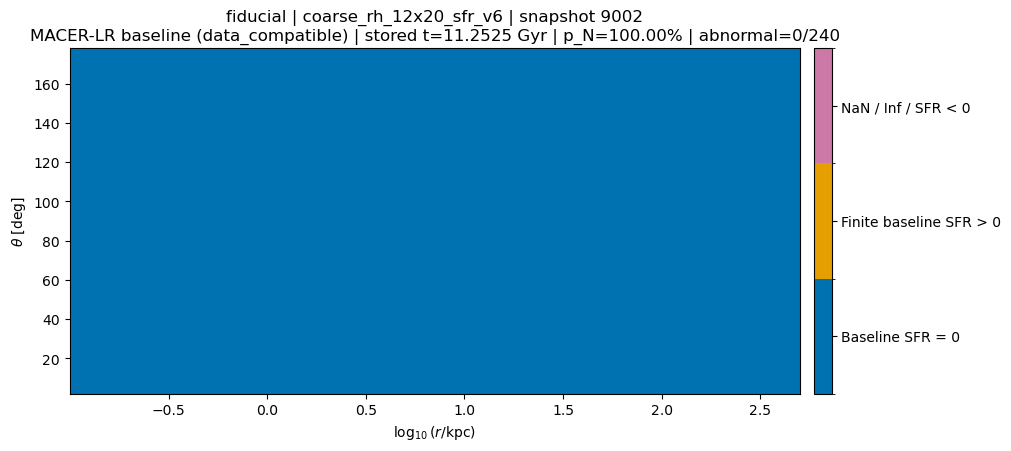

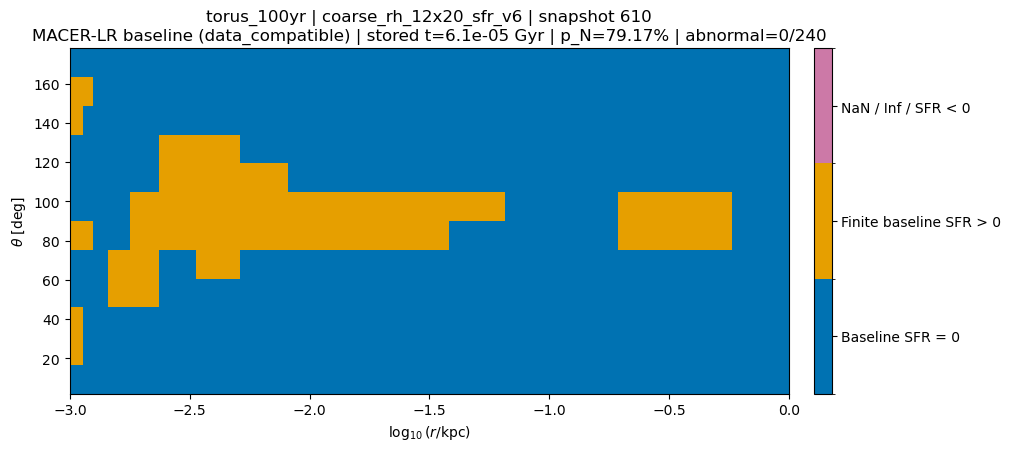

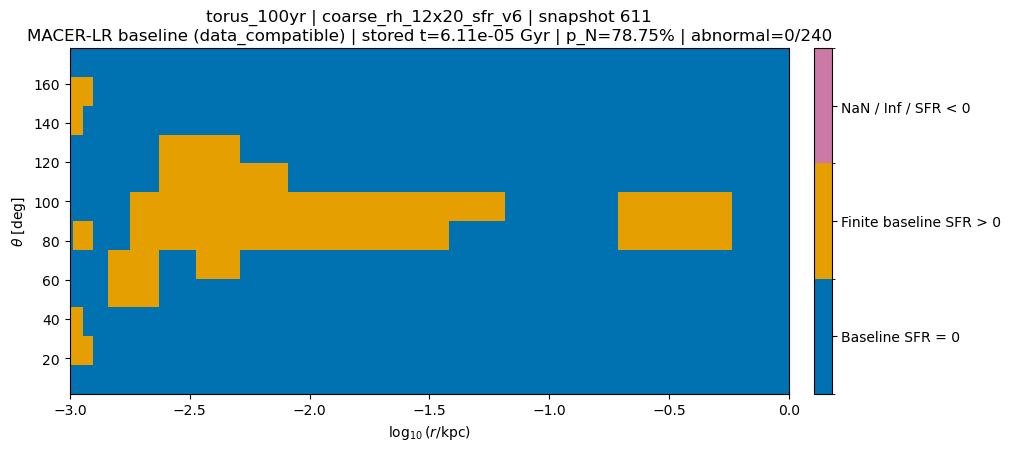

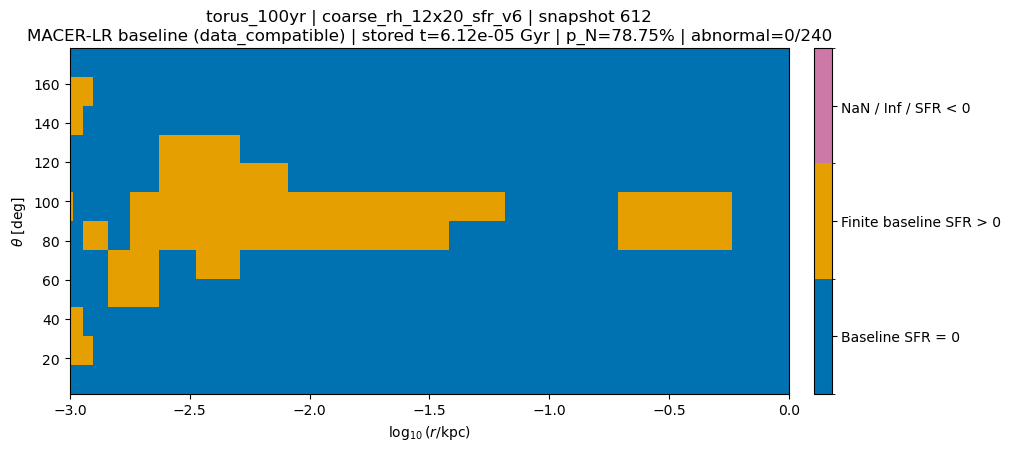

,galaxy,coarse_dir,baseline_mode,snapshot_index,error,n_total,n_zero,n_nonzero,n_abnormal,p_N,p_abnormal,time_gyr,configured_time_gyr,time_mapping_mismatch,file,sfr_source,status
0,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,9000,,240,234,6,0,0.975000,0.0,11.250000,11.82375,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok
1,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,9001,,240,236,4,0,0.983333,0.0,11.251250,11.82500,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok
2,fiducial,coarse_rh_12x20_sfr_v6,data_compatible,9002,,240,240,0,0,1.000000,0.0,11.252500,11.82625,True,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok
3,torus_100yr,coarse_rh_12x20_sfr_v6,data_compatible,610,,240,190,50,0,0.791667,0.0,0.000061,NaN,False,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok
4,torus_100yr,coarse_rh_12x20_sfr_v6,data_compatible,611,,240,189,51,0,0.787500,0.0,0.000061,NaN,False,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok
5,torus_100yr,coarse_rh_12x20_sfr_v6,data_compatible,612,,240,189,51,0,0.787500,0.0,0.000061,NaN,False,D:\research\ai+MACERsimulation\MACNet-v1\data\...,sfr_supervision/data_compatible/cell_sfr_baseline,ok


In [10]:
# Coarse 单帧掩码绘图 cell：参数指定、文件读取和单帧绘图独立于 raw cell。
COARSE_MASK_SNAPSHOTS = {'fiducial':[9000,9001,9002],'torus_100yr':[610,611,612]}
# COARSE_MASK_SNAPSHOTS = {'fiducial': {'coarse_rh_12x20_sfr_v6':[0,100], 'coarse_rh_8x8_sfr_v6':999},
#                          'model_0_75': {'coarse_rh_12x20_sfr_v6':[46,999]}}


def plot_coarse_mask(frame,key,directory,mode,time_unit):
    summary = coarse_summarize(frame['sfr'])
    fig, ax = plt.subplots(figsize=(10,4.4),constrained_layout=True)
    cmap = ListedColormap(['#0072B2','#E69F00','#CC79A7'])
    norm = BoundaryNorm([-.5,.5,1.5,2.5],cmap.N)
    mesh = ax.pcolormesh(np.log10(frame['r_edges']),np.rad2deg(frame['theta_edges']),
                         coarse_classify(frame['sfr']),cmap=cmap,norm=norm,shading='flat',rasterized=True)
    scale = {'Gyr':1.,'Myr':1e3,'yr':1e9}[time_unit]
    ax.set(xlabel=r'$\log_{10}(r/\mathrm{kpc})$',ylabel=r'$\theta$ [deg]',
           title=f'{key} | {directory} | snapshot {frame["snapshot_index"]}\n'
                 f'MACER-LR baseline ({mode}) | stored t={frame["time_gyr"]*scale:.8g} {time_unit} | '
                 f'p_N={summary["p_N"]:.2%} | abnormal={summary["n_abnormal"]}/{summary["n_total"]}')
    bar = fig.colorbar(mesh,ax=ax,ticks=[0,1,2],pad=.02)
    bar.ax.set_yticklabels(['Baseline SFR = 0','Finite baseline SFR > 0','NaN / Inf / SFR < 0'])
    plt.show()
    return fig


def plot_coarse_selected_masks(selection,mode,time_unit):
    figures, records = {}, []
    for name, choices in selection.items():
        key = coarse_galaxy_key(name)
        if not isinstance(choices,dict):
            choices = {COARSE_DEFAULT_DIRNAME: choices}
        for directory, values in choices.items():
            directory = coarse_directory_name(directory)
            indices = coarse_indices(values)
            try:
                indexed = coarse_files(key,directory)
            except (OSError,ValueError) as exc:
                print(f'{key}/{directory}：{exc}')
                records.extend(dict(galaxy=key,coarse_dir=directory,snapshot_index=index,
                                    status='unavailable',error=str(exc)) for index in indices)
                continue
            for index in indices:
                row = dict(galaxy=key,coarse_dir=directory,baseline_mode=mode,snapshot_index=index,error='')
                if index in COARSE_EXCLUDED[key]:
                    row.update(status='excluded',error='排除清单；未读取')
                elif index not in indexed:
                    row.update(status='missing',error='没有对应编号的 coarse 文件')
                else:
                    try:
                        frame = read_coarse_sfr(indexed[index],key,mode)
                        if frame['time_mapping_mismatch']:
                            warnings.warn(f'{key}/{directory}/{index} coarse 存储时间 {frame["time_gyr"]} Gyr '
                                          f'与当前配置 {frame["configured_time_gyr"]} Gyr 不符；图中保留存储时间。')
                        figures[(key,directory,index)] = plot_coarse_mask(frame,key,directory,mode,time_unit)
                        row.update(coarse_summarize(frame['sfr']))
                        row.update(time_gyr=frame['time_gyr'],configured_time_gyr=frame['configured_time_gyr'],
                                   time_mapping_mismatch=frame['time_mapping_mismatch'],file=str(indexed[index]),sfr_source=frame['sfr_source'],
                                   status='abnormal' if row['n_abnormal'] else 'ok')
                    except (OSError,ValueError,KeyError,TypeError) as exc:
                        row.update(status='read_error',error=f'{type(exc).__name__}: {exc}')
                if row['error']:
                    print(f'{key}/{directory}/{index}：{row["error"]}')
                records.append(row)
    return figures,pd.DataFrame(records)


coarse_mask_figures,coarse_mask_summary = plot_coarse_selected_masks(COARSE_MASK_SNAPSHOTS,COARSE_BASELINE_MODE,COARSE_TIME_UNIT)
if not coarse_mask_summary.empty:
    display(coarse_mask_summary)
